# 07 — Model Evaluation

Evaluasi dilakukan pada test set berbasis rekaman yang tidak digunakan untuk melatih model. Probabilitas empat subband DWT dirata-ratakan per segmen, sesuai inferensi di notebook ESP32. Metrik: accuracy, precision, recall/sensitivity, F1-score, confusion matrix, dan specificity one-vs-rest.

In [7]:
from pathlib import Path
import pickle
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

current_dir = Path.cwd()
project_candidates = [current_dir, *current_dir.parents]
project_candidates.extend(path for path in current_dir.iterdir() if path.is_dir())
ROOT = next((path.resolve() for path in project_candidates
             if (path / "notebooks").is_dir() and (path / "data").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Folder project ECG_2D_CNN_Project tidak ditemukan.")
DWT_DIR = ROOT / "data" / "processed" / "05_dwt"
MODEL_DIR = ROOT / "06_model_chf_nsr"
CLASS_NAMES = ["CHF", "NSR"]
RANDOM_STATE = 42


In [8]:
X = np.load(DWT_DIR / "X_images.npy").astype(np.float32)
meta = pd.read_csv(DWT_DIR / "images_metadata.csv")
le = LabelEncoder().fit(CLASS_NAMES)
y = le.transform(meta["label"].to_numpy())
records = meta[["record_id", "label"]].drop_duplicates()
trainval_records, test_records = train_test_split(
    records, test_size=0.15, stratify=records["label"], random_state=RANDOM_STATE
)
_, _ = train_test_split(
    trainval_records, test_size=0.17647, stratify=trainval_records["label"],
    random_state=RANDOM_STATE + 1
)
test_idx = np.flatnonzero(meta["record_id"].isin(test_records["record_id"]).to_numpy())
X_test, y_test = X[test_idx], y[test_idx]
test_meta = meta.iloc[test_idx].reset_index(drop=True)
model = tf.keras.models.load_model(MODEL_DIR / "best_model.keras")
print("Test records:", test_meta[["record_id", "label"]].drop_duplicates().shape[0])
print("Test class counts (records):", test_meta[["record_id", "label"]].drop_duplicates()["label"].value_counts().to_dict())


Test records: 10
Test class counts (records): {'CHF': 5, 'NSR': 5}


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
Akurasi test per segmen: 0.9263 (800 segmen)
              precision    recall  f1-score   support

         CHF     0.9169    0.9375    0.9271       400
         NSR     0.9361    0.9150    0.9254       400

    accuracy                         0.9263       800
   macro avg     0.9265    0.9263    0.9262       800
weighted avg     0.9265    0.9263    0.9262       800



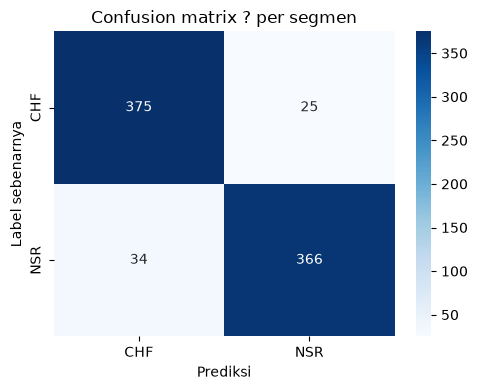

Akurasi test setelah rata-rata segmen per rekaman: 1.0000 (10 rekaman)
              precision    recall  f1-score   support

         CHF     1.0000    1.0000    1.0000         5
         NSR     1.0000    1.0000    1.0000         5

    accuracy                         1.0000        10
   macro avg     1.0000    1.0000    1.0000        10
weighted avg     1.0000    1.0000    1.0000        10



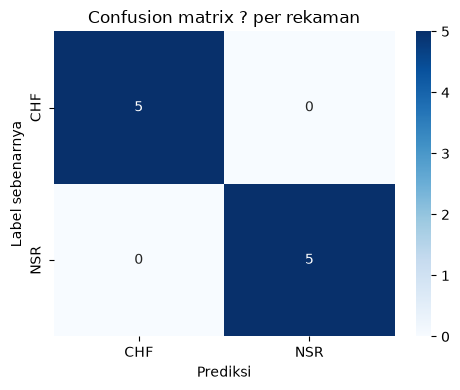

In [9]:
prob = model.predict(X_test, batch_size=128, verbose=1)
y_pred = np.argmax(prob, axis=1)
class_names = list(le.classes_)

segment_accuracy = accuracy_score(y_test, y_pred)
print(f"Akurasi test per segmen: {segment_accuracy:.4f} ({len(y_test)} segmen)")
print(classification_report(y_test, y_pred, target_names=class_names, digits=4, zero_division=0))

segment_cm = confusion_matrix(y_test, y_pred, labels=np.arange(len(class_names)))
plt.figure(figsize=(5, 4))
sns.heatmap(segment_cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Prediksi")
plt.ylabel("Label sebenarnya")
plt.title("Confusion matrix ? per segmen")
plt.tight_layout()
plt.show()

record_results = test_meta[["record_id", "label"]].copy()
for index, name in enumerate(class_names):
    record_results[f"prob_{name}"] = prob[:, index]
record_probs = record_results.groupby("record_id")[[f"prob_{name}" for name in class_names]].mean()
record_truth = record_results.groupby("record_id")["label"].first()
record_pred = np.argmax(record_probs.to_numpy(), axis=1)
record_true = le.transform(record_truth.loc[record_probs.index].to_numpy())
record_accuracy = accuracy_score(record_true, record_pred)
print(f"Akurasi test setelah rata-rata segmen per rekaman: {record_accuracy:.4f} ({len(record_true)} rekaman)")
print(classification_report(record_true, record_pred, target_names=class_names, digits=4, zero_division=0))
record_cm = confusion_matrix(record_true, record_pred, labels=np.arange(len(class_names)))
plt.figure(figsize=(5, 4))
sns.heatmap(record_cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Prediksi")
plt.ylabel("Label sebenarnya")
plt.title("Confusion matrix ? per rekaman")
plt.tight_layout()
plt.show()


**Interpretasi:** metrik per rekaman merata-ratakan seluruh window dari rekaman yang tidak pernah dipakai saat training; metrik per segmen menunjukkan prediksi pada masing-masing window. Jumlah rekaman uji kecil, jadi akurasi ini memiliki ketidakpastian dan bukan validasi klinis.
